In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from funcs import *


In [2]:
zeros = lambda t, x, y: np.zeros_like(x, dtype=float)
ones  = lambda t, x, y: np.ones_like(x, dtype=float)

# 1: u = 0, v = -c*y
funcs1 = [
    zeros,                                        # u
    zeros,                                        # u_x
    zeros,                                        # u_y
    zeros,                                        # u_xx
    zeros,                                        # u_yy
    zeros,                                        # u_xy
    lambda t, x, y, c=0.5: -c * y,                # v
    zeros,                                        # v_x
    lambda t, x, y, c=0.5: -c * np.ones_like(y, dtype=float),  # v_y
    zeros,                                        # v_xx
    zeros,                                        # v_yy
    zeros,                                        # v_xy
]
f1 = Formulation(2, 2, 2.0, funcs1)

# 2: u = -y, v = 0
funcs2 = [
    lambda t, x, y: -y,                           # u
    zeros,                                        # u_x
    lambda t, x, y: -np.ones_like(y, dtype=float),  # u_y
    zeros,                                        # u_xx
    zeros,                                        # u_yy
    zeros,                                        # u_xy
    zeros,                                        # v
    zeros,                                        # v_x
    zeros,                                        # v_y
    zeros,                                        # v_xx
    zeros,                                        # v_yy
    zeros,                                        # v_xy
]
f2 = Formulation(2, 2, 1, funcs2)

# 3: sinusoidal cellular flow
funcs3 = [
    lambda t, x, y, c=6, w=np.pi/10: -c * np.sin(w * y),         # u
    zeros,                                                       # u_x
    lambda t, x, y, c=6, w=np.pi/10: -c * w * np.cos(w * y),     # u_y
    zeros,                                                       # u_xx
    lambda t, x, y, c=6, w=np.pi/10:  c * w**2 * np.sin(w * y),  # u_yy
    zeros,                                                       # u_xy
    lambda t, x, y, c=6, w=np.pi/10:  c * np.sin(w * x),         # v
    lambda t, x, y, c=6, w=np.pi/10:  c * w * np.cos(w * x),     # v_x
    zeros,                                                       # v_y
    lambda t, x, y, c=6, w=np.pi/10: -c * w**2 * np.sin(w * x),  # v_xx
    zeros,                                                       # v_yy
    zeros,                                                       # v_xy
]
f3 = Formulation(2, 2, 10, funcs3)

# 4: linear strain u = a*x, v = b*y
funcs4 = [
    lambda t, x, y, a=0.5, b=0.7: a * x,                             # u
    lambda t, x, y, a=0.5, b=0.7: a * np.ones_like(x, dtype=float),  # u_x
    zeros,                                                           # u_y
    zeros,                                                           # u_xx
    zeros,                                                           # u_yy
    zeros,                                                           # u_xy
    lambda t, x, y, a=0.5, b=0.7: b * y,                             # v
    zeros,                                                           # v_x
    lambda t, x, y, a=0.5, b=0.7: b * np.ones_like(y, dtype=float),  # v_y
    zeros,                                                           # v_xx
    zeros,                                                           # v_yy
    zeros,                                                           # v_xy
]
f4 = Formulation(2, 2, 1.0, funcs4)

# 5: u = -y^2, v = 0
funcs5 = [
    lambda t, x, y: -y**2,                                 # u
    zeros,                                                 # u_x
    lambda t, x, y: -2 * y,                                # u_y
    zeros,                                                 # u_xx
    lambda t, x, y: -2 * np.ones_like(y, dtype=float),     # u_yy
    zeros,                                                 # u_xy
    zeros,                                                 # v
    zeros,                                                 # v_x
    zeros,                                                 # v_y
    zeros,                                                 # v_xx
    zeros,                                                 # v_yy
    zeros,                                                 # v_xy
]
f5 = Formulation(2, 2, 1.0, funcs5)

# 6: time-dependent shear u = -t*y, v = 0
funcs6 = [
    lambda t, x, y: -t * y,                                # u
    zeros,                                                 # u_x
    lambda t, x, y: -t * np.ones_like(y, dtype=float),     # u_y
    zeros,                                                 # u_xx
    zeros,                                                 # u_yy
    zeros,                                                 # u_xy
    zeros,                                                 # v
    zeros,                                                 # v_x
    zeros,                                                 # v_y
    zeros,                                                 # v_xx
    zeros,                                                 # v_yy
    zeros,                                                 # v_xy
]
f6 = Formulation(2, 2, 1.0, funcs6)

formulations = [f1, f2, f3, f4, f5, f6]

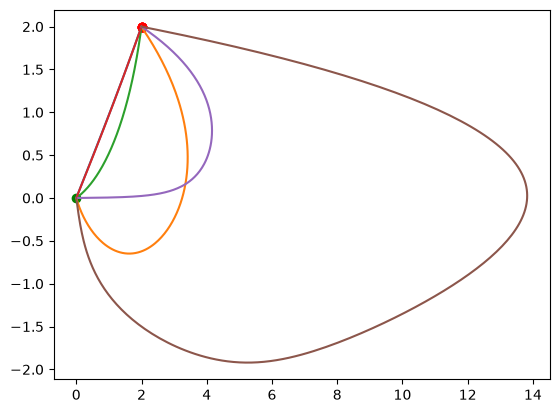

In [3]:
phi_range = np.linspace(0, np.pi, 10)
T_range = np.linspace(0.1, 10, 10)
num_iters = 20
num_points = 200

for f in formulations:
    f.solve_shooting(phi_range, T_range, num_iters, num_points)

plot_formulations_together(formulations, method="shooting")

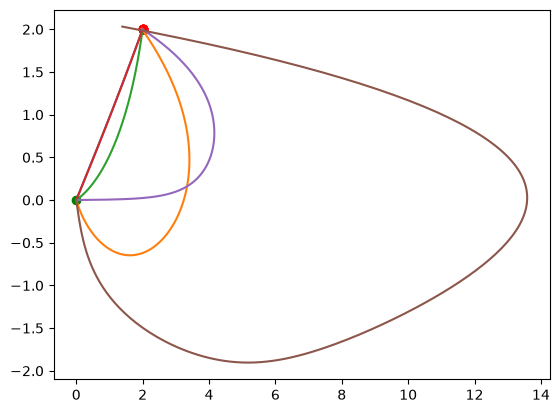

In [4]:
num_iters = 20
num_points = 200
stepsize = 0.02

for f in formulations:
    f.solve_wind_adj(stepsize, num_points, num_iters)

plot_formulations_together(formulations, method="wind_adj")

T local: 1.4142135623730951
T local: 1.4191344939972186
T local: 1.4238879302150627
T local: 1.4291119905599223
T local: 1.4344636846097165
T local: 1.4399017220762371
T local: 1.4454225618373924
T local: 1.4510274379362995
T local: 1.4567182404685752
T local: 1.4624970034174278
T local: 1.4687851828891667
T local: 1.4743794078369996
T local: 1.480818619155349
T local: 1.4865897294184185
T local: 1.4932373091015332
T local: 1.4996231936242903
T local: 1.5060910641052394
T local: 1.5126650067182534
T local: 1.5193492166374485
T local: 1.526146752223994
T local: 1.5330607140351713
T local: 1.540094324644709
T local: 1.5472509401180878
T local: 1.5545340576566267
T local: 1.5619473234950283
T local: 1.5694945412947312
T local: 1.5771796811337948
T local: 1.5850068891708176
T local: 1.5929804979965492
T local: 1.6011050377326494
T local: 1.6093852479463138
T local: 1.61782609053419
T local: 1.6264327635315494
T local: 1.635210716020498
T local: 1.6441656641990996
T local: 1.653303608810598

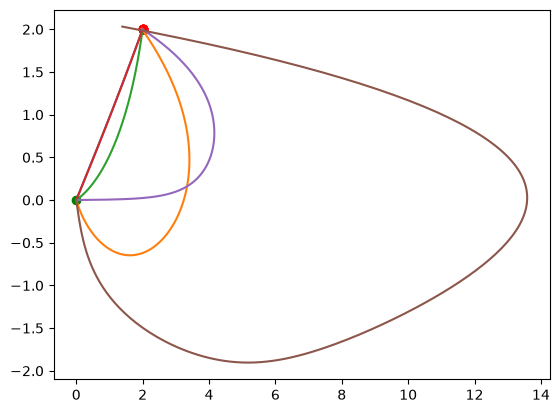

In [5]:
num_iters = 20
num_points = 200
stepsize = 0.02
dphi = np.pi/8
branch_count = 5

for f in formulations:
    f.solve_branch_wind_adj(stepsize, num_points, num_iters, dphi, branch_count)

plot_formulations_together(formulations, method="branch_wind_adj")